# Dr.Copper v2 - Phase 2: Time-series analysis

In [1]:
import warnings

import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import HTML, display

import dr_copper_v2 as dc
from dr_copper_v2.data_loader import ROOT

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 2

warnings.filterwarnings("ignore")

## 1 - Load Phase 1 outputs

In [2]:
data_dir = ROOT / "data" / "processed"
raw = pd.read_parquet(data_dir / "raw_development.parquet")
features = pd.read_parquet(data_dir / "features_development.parquet")

prices = raw["copper"].loc["2012-01-01":"2022-12-31"]
log_returns = features["copper_ret1d"]
cper = pd.DataFrame({"close": prices, "log_return": log_returns})

In [3]:
data1 = cper.loc["2012-01-01":"2016-12-31"]
data2 = cper.loc["2017-01-01":"2022-12-31"]

## 2 - Stationarity: a brief check

Following Tsay (third edition, §2.7.5, p. 77), ADF tests a **unit-root null**. We test log prices and daily log returns with a constant (allowing a nonzero mean), no deterministic linear trend, AIC-selected augmentation lags and a 5% rejection threshold.

In [4]:
stationarity_data = pd.DataFrame(
    {
        "log_price": np.log(data1["close"]),
        "log_return": data1["log_return"],
    }
)
adf_results = dc.adf_summary(stationarity_data, regression="c")
adf_results[["adf_statistic", "p_value", "reject_unit_root"]]

,adf_statistic,p_value,reject_unit_root
feature,,,
log_price,-1.331145,6.148056e-01,False
log_return,-9.027178,5.569442e-15,True


The results match our expectation: log prices do not reject the unit-root null (p ≈ 0.615), while daily log returns reject it (p < 0.001). This supports continuing with returns. Failure to reject does not prove a unit root, and rejection does not establish stable variance or rule out structural changes.

## 3 - Return dependence

ACF measures correlation with earlier returns; PACF measures the remaining linear relationship at a lag after accounting for intervening lags. Squared demeaned returns help distinguish dependence in return size from dependence in signed returns. Dashed lines are approximate 95% IID reference limits.

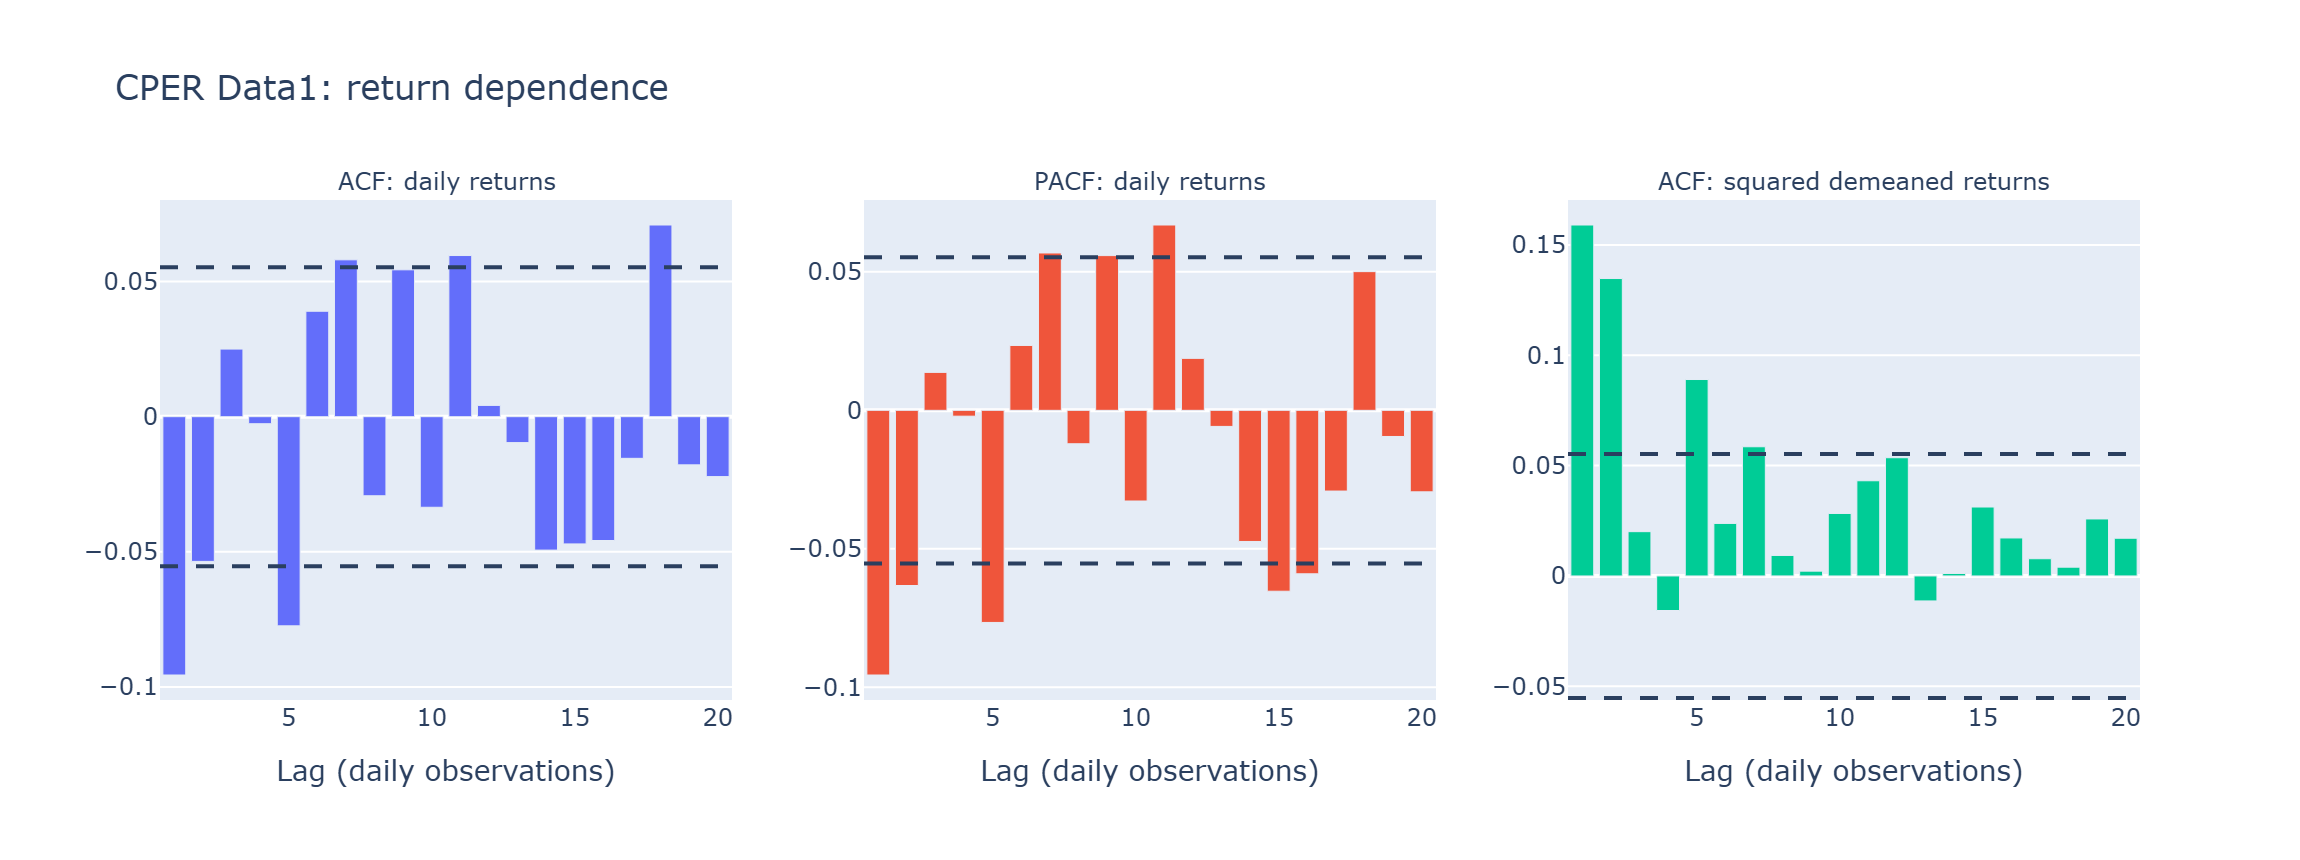

In [5]:
daily_returns = data1["log_return"]

fig = dc.plot_return_dependence(daily_returns, nlags=20)
fig.update_layout(title="CPER Data1: return dependence")
fig.show()

Ljung-Box tests whether all autocorrelations through the stated lag are zero, not just that one lag.

In [6]:
dependence = dc.return_dependence_summary(daily_returns, lags=[5, 10, 20])

display(
    HTML(
        dependence.to_html(
            formatters={
                "Q": "{:.2f}".format,
                "p_value": "{:.2e}".format,
            },
            border=0,
        )
    )
)

Daily returns show several small autocorrelations, including negative lag-one correlation of approximately −0.096. Ljung–Box rejects zero autocorrelation jointly through lags 5, 10 and 20 (p < 0.001). These results motivate investigating a dynamic mean equation, but the ACF/PACF do not identify a clear model order.

Squared demeaned returns also show dependence (p < 0.001), motivating later volatility analysis.

## 4 - Mean-model comparison: Data1

Compare **zero mean, constant mean and AR(1)-AR(20)** once on Data1.

All candidates reserve the first 20 returns as lag history (`hold_back=20`). `delta_BIC` measures the gap from the lowest BIC.

In [7]:
mean_comparison, mean_fits = dc.compare_mean_models(daily_returns, max_lag=20)

display(
    HTML(
        mean_comparison.to_html(
            formatters={"BIC": "{:.2f}".format, "delta_BIC": "{:.2f}".format},
            border=0,
        )
    )
)

,ar_order,nobs,parameters,BIC,delta_BIC
model,,,,,
Zero,0,1236,1,-7026.43,0.00
AR(1),1,1236,3,-7024.08,2.35
AR(2),2,1236,4,-7022.53,3.90
Constant,0,1236,2,-7020.37,6.06
AR(3),3,1236,5,-7015.70,10.73
AR(5),5,1236,7,-7010.16,16.26
AR(4),4,1236,6,-7008.69,17.74
AR(6),6,1236,8,-7003.53,22.90
AR(7),7,1236,9,-7000.27,26.16


Zero mean has the lowest BIC. AR(1) is the best dynamic candidate, with BIC about 2.35 higher; adding further lags does not improve on zero mean under this criterion.

### Residual checks

Inspect **zero mean, constant mean and AR(1)**: the two simple benchmarks and the best dynamic candidate by BIC.

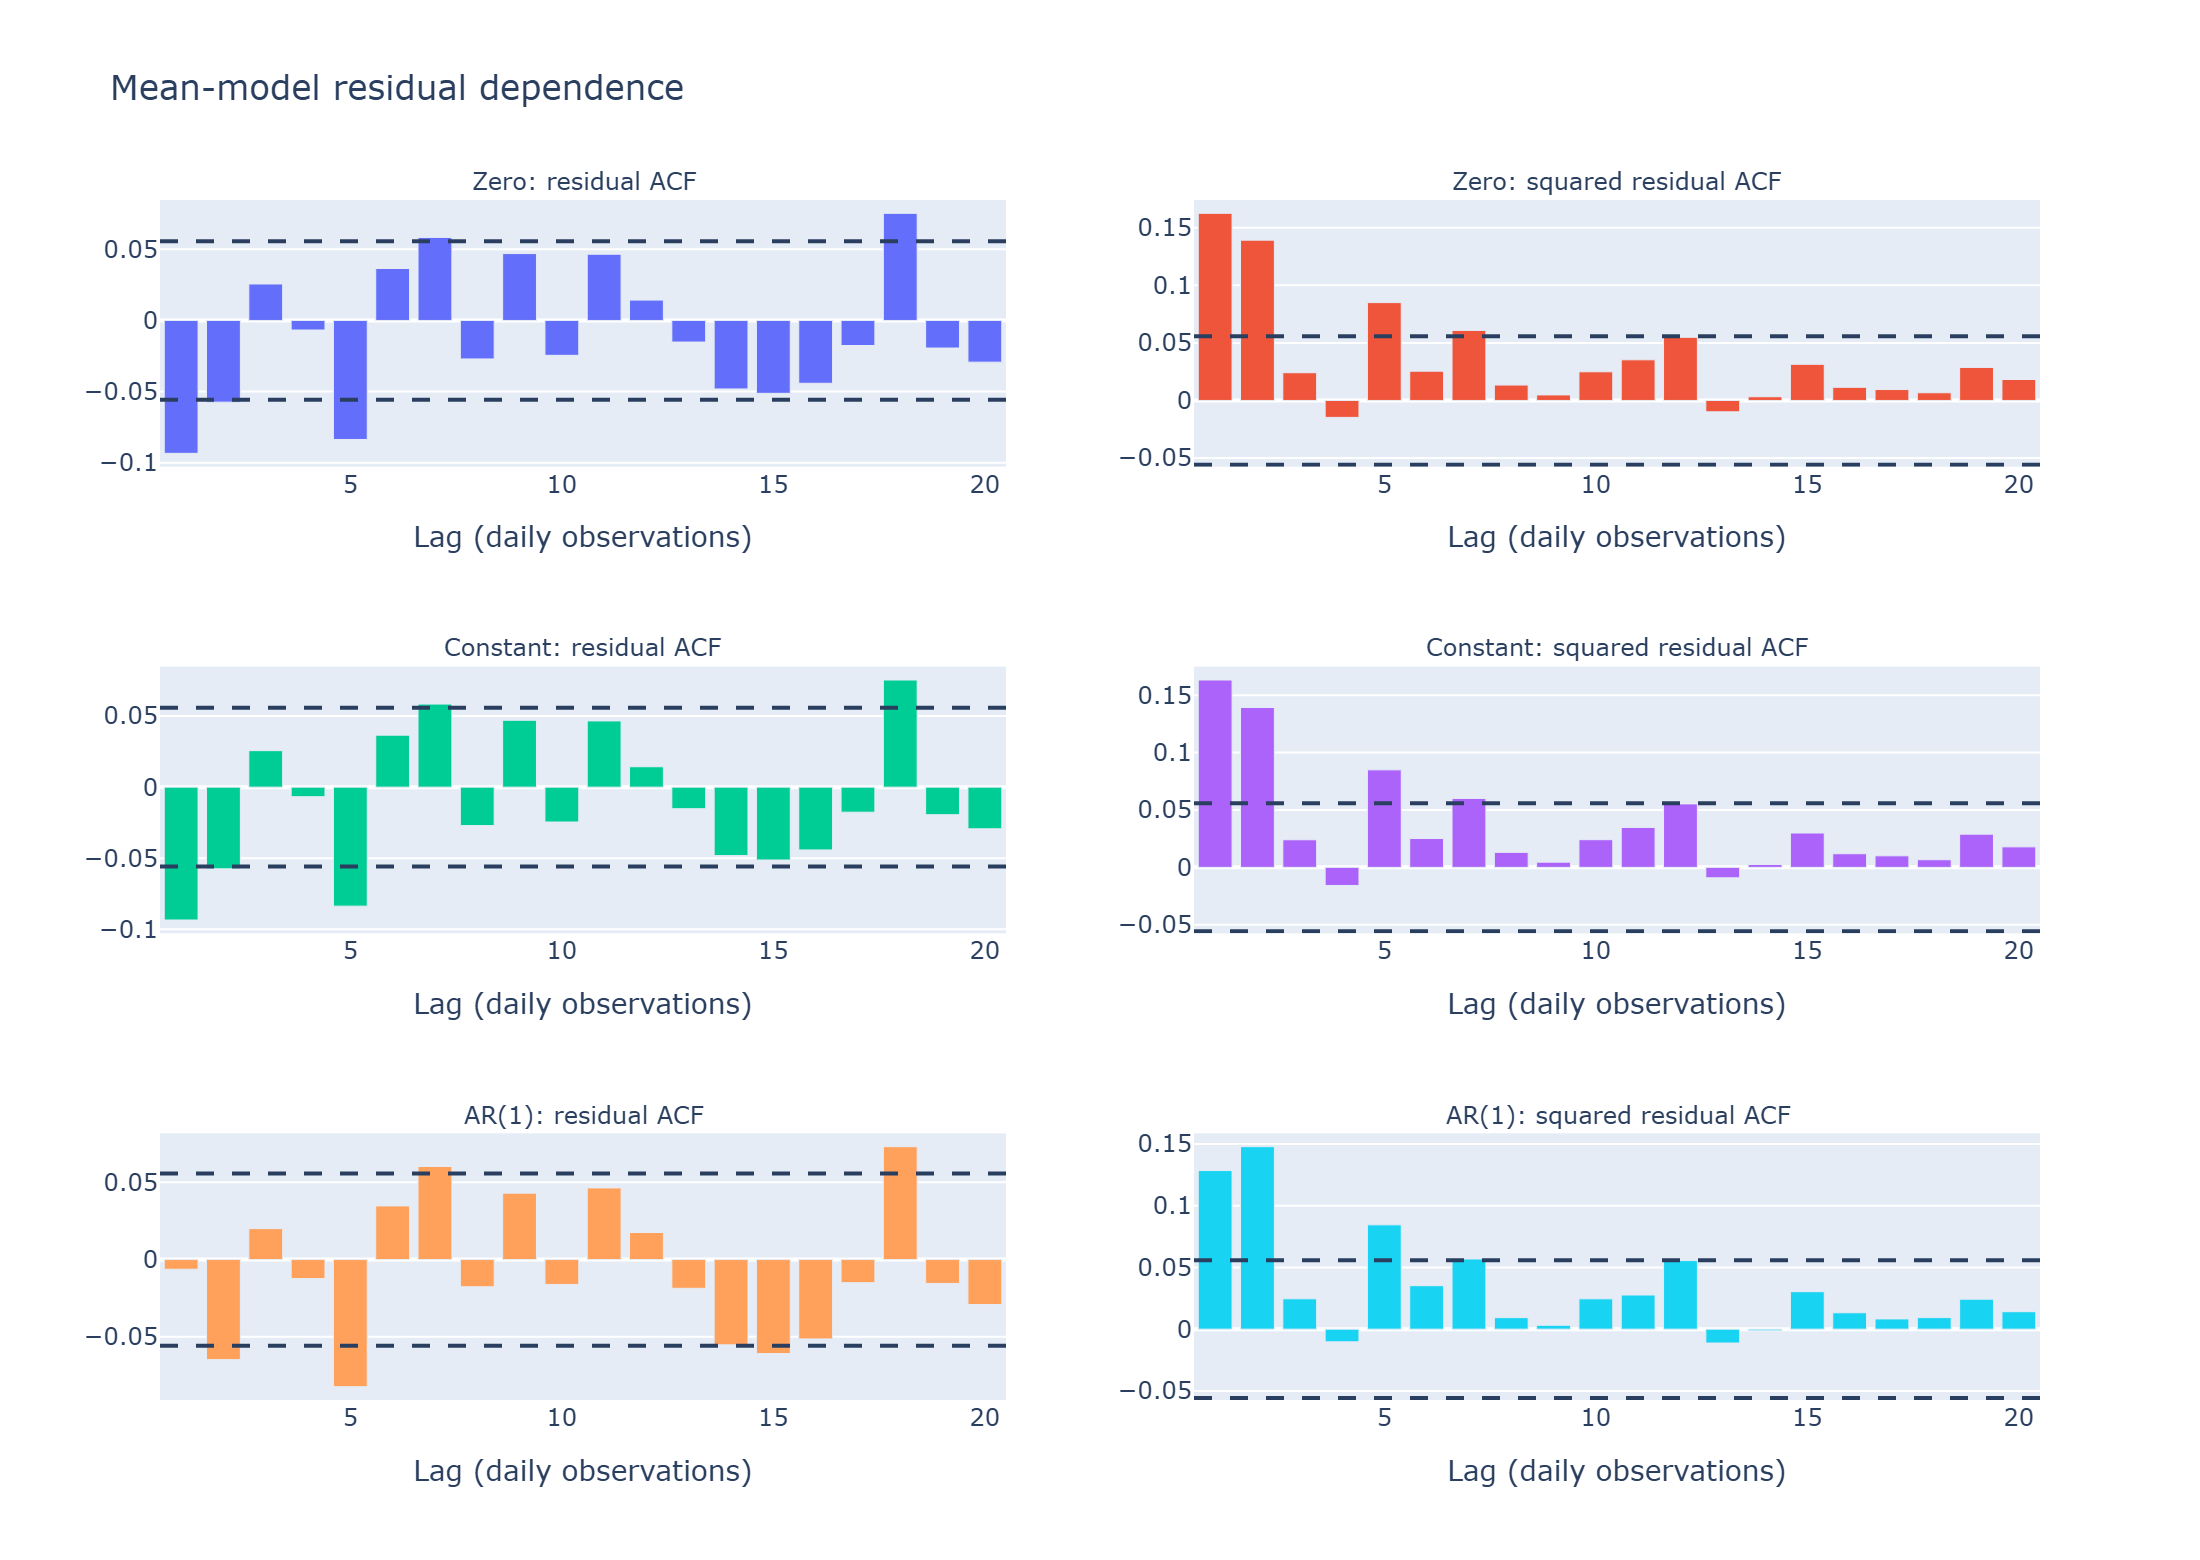

In [8]:
residual_fits = {name: mean_fits[name] for name in ["Zero", "Constant", "AR(1)"]}
fig = dc.plot_mean_residuals(residual_fits, nlags=20)
fig.show()

In [9]:
residual_checks = dc.mean_residual_summary(residual_fits, lags=[5, 10, 20])

display(
    HTML(
        residual_checks.to_html(
            formatters={
                "residual_Q": "{:.2f}".format,
                "residual_p_value": "{:.2e}".format,
                "squared_Q": "{:.2f}".format,
                "squared_p_value": "{:.2e}".format,
            },
            border=0,
        )
    )
)

AR(1) reduces lag-one residual correlation, but Ljung-Box still gives p < 0.01 at all three horizons. Squared residuals remain dependent for every candidate (p < 0.001). Thus AR(1) does not remove all detected dependence, while zero mean's BIC advantage does not establish uncorrelated residuals.

## 5 - Forecast comparison: Data2

Compare **zero, constant and AR(1)** using the 72 saved monthly folds. Fit on preceding history with `hold_back=1`: AR(1) needs one preceding return, and all three models use the same estimation observations.

Predict the next **one and five sessions' cumulative log returns**. AR(1) recursively predicts future returns and sums them, using its origin's parameters throughout.

`MSE_vs_zero_pct` is the percentage change from zero mean's MSE (negative means improvement). Five-session outcomes overlap; this is a descriptive development comparison, not an independence-based significance test.

In [10]:
splits = pd.read_parquet(data_dir / "pca" / "n_components_12" / "splits.parquet")
development_returns = cper["log_return"]
forecast_horizons = (1, 5)

mean_forecasts = dc.forecast_mean_models(
    development_returns, splits, horizons=forecast_horizons, hold_back=1
)

In [11]:
future_returns = pd.DataFrame(
    {
        h: sum(development_returns.shift(-step) for step in range(1, h + 1))
        for h in forecast_horizons
    }
)
future_returns.index.name = "date"
future_returns.columns.name = "horizon"
actuals = future_returns.stack().rename("actual")

forecast_errors = mean_forecasts.join(actuals, on=["date", "horizon"]).dropna(
    subset=["actual"]
)
forecast_errors["squared_error"] = (
    forecast_errors["forecast"] - forecast_errors["actual"]
) ** 2

In [12]:
forecast_summary = forecast_errors.groupby(["horizon", "model"]).agg(
    nobs=("squared_error", "size"), MSE=("squared_error", "mean")
)
zero_mse = forecast_summary.xs("Zero", level="model")["MSE"]
forecast_summary["MSE_vs_zero_pct"] = 100 * (
    forecast_summary["MSE"].div(zero_mse, level="horizon") - 1
)

display(
    HTML(
        forecast_summary.to_html(
            formatters={"MSE": "{:.6e}".format, "MSE_vs_zero_pct": "{:+.2f}".format},
            border=0,
        )
    )
)

Daily MSE is nearly identical: AR(1) improves on zero mean by about 0.03%, while constant mean is about 0.09% worse. At five sessions, zero mean has the lowest MSE; AR(1) and constant mean are about 0.42% and 0.49% worse. There is no clear forecast-error advantage here from adding mean dynamics. These development results inform the next mean-model decision; they do not establish statistical equivalence or trading profitability.

## 6 - Mean-model decision for Phase 3

Use **zero mean**, corresponding to `mean="Zero"` in Phase 3's GARCH model. Zero mean has the lowest Data1 BIC. On Data2, AR(1)'s daily MSE improvement is only about 0.03%, while its five-session MSE is about 0.42% worse than zero mean. These results support keeping the mean equation simple.

## 7 - Direction benchmarks for Phase 4

For five-session direction, define $y_t=1$ when $Close_{t+5}/Close_t-1>0$, otherwise $y_t=0$ (zero returns belong to **non-up**). Unavailable future outcomes remain missing.

| Benchmark | Direction forecast | Purpose |
|---|---|---|
| Always-up | Up every day | Does the model beat simply predicting a rise? |
| Training-majority | Up if more than half the eligible training labels are up; otherwise non-up | Does the model beat the most common training direction? |
| L2-regularized logistic regression | Up if its model output exceeds 0.5; otherwise non-up | Does XGBoost improve on a simpler classifier using the same inputs and representation? |

Compare **direction accuracy** on identical forecast dates and monthly folds. Apply the same threshold rule to XGBoost: up above 0.5, otherwise non-up. There are no random draws. Training-majority stays fixed within each month and is recalculated at the next refit.